# 01 — Exploratory Data Analysis (EDA)

**Project:** AI-Based IoT Sensor Anomaly Detection (ESP32 + DHT11)  
**Author:** Dungu Avinash Reddy | Roll RK3P25KZA09 | Reg. 12509090  

This notebook inspects all immutable raw telemetry datasets under `data/raw/`, characterizes
sampling intervals, duplicates, unlabeled normal-set anomalies, and live DHT11 hardware resolution.

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'config.yaml').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import config
print(f'Project root: {PROJECT_ROOT}')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from preprocess.clean_datasets import load_raw_normal

sns.set_style('whitegrid')
raw_dir = config.raw_dir
normal = load_raw_normal(raw_dir / 'normal_data.csv')
pilot = pd.read_csv(raw_dir / 'pilot_data.csv', parse_dates=['timestamp'])
test = pd.read_csv(raw_dir / 'test.csv', parse_dates=['timestamp'])
test_labels = pd.read_csv(raw_dir / 'test_labels.csv', parse_dates=['start', 'end'])
live_files = sorted(raw_dir.glob('live_*.csv'))
live = pd.concat([pd.read_csv(p, parse_dates=['timestamp']) for p in live_files], ignore_index=True) if live_files else pd.DataFrame()

for name, df in [('normal_data.csv', normal), ('pilot_data.csv', pilot), ('test.csv', test), ('live_2026-11-10', live)]:
    if len(df):
        print(f'{name:18s}: rows={len(df):6d} | T=[{df.temperature.min():.1f}, {df.temperature.max():.1f}] C | '
              f'H=[{df.humidity.min():.1f}, {df.humidity.max():.1f}] % | '
              f'{df.timestamp.min()} -> {df.timestamp.max()}')

Project root: c:\Users\Avinash Reddy\OneDrive\Desktop\Iot anomaly detection
normal_data.csv   : rows= 49728 | T=[22.4, 27.0] C | H=[46.8, 97.2] % | 2026-10-29 16:39:00 -> 2026-11-01 17:52:32
pilot_data.csv    : rows=  3087 | T=[26.0, 32.9] C | H=[44.4, 95.8] % | 2026-10-27 22:02:14 -> 2026-10-28 01:05:47
test.csv          : rows=    56 | T=[26.2, 34.2] C | H=[59.3, 82.1] % | 2026-10-27 22:02:14 -> 2026-10-27 22:04:05
live_2026-11-10   : rows=    59 | T=[28.1, 29.7] C | H=[53.7, 59.8] % | 2026-11-10 17:16:03 -> 2026-11-10 17:20:32


## 1. Duplicate, Burst & Sampling Interval Analysis (`normal_data.csv`)

Key discoveries from the raw telemetry audit:
- `normal_data.csv` contains **12,776 exact duplicate rows** (49,728 -> 36,952 rows).
- Same-second USB serial buffer bursts produce repeated timestamps (36,952 -> 36,663 rows).
- Nominal ESP32 + DHT11 sampling cadence is **2.0 s** (0.5 Hz), with occasional recording gaps (>10 s).
- Real DHT11 telemetry exhibits **0.1 C / 0.1% RH resolution** steps (e.g., `25.9`, `26.0`).

In [2]:
exact_dups = int(normal.duplicated().sum())
dedup = normal.drop_duplicates().sort_values('timestamp', kind='stable').reset_index(drop=True)
ts_dups = int(dedup.duplicated(subset=['timestamp']).sum())
intervals = dedup['timestamp'].diff().dt.total_seconds().dropna()

print(f'Raw normal rows        : {len(normal):,}')
print(f'Exact duplicate rows   : {exact_dups:,}')
print(f'Same-timestamp bursts  : {ts_dups:,}')
print(f'Intervals == 2.0s      : {(intervals == 2.0).sum():,} ({(intervals == 2.0).mean()*100:.1f}%)')
print(f'Macro gaps (>10s)      : {(intervals > config.gap_threshold_sec).sum()}')
print(f'Sub-degree fractional T: {(dedup.temperature % 1 != 0).mean()*100:.1f}% non-integer')

Raw normal rows        : 49,728
Exact duplicate rows   : 12,776
Same-timestamp bursts  : 289
Intervals == 2.0s      : 35,727 (96.7%)
Macro gaps (>10s)      : 10
Sub-degree fractional T: 95.7% non-integer


## 2. Unlabeled Disturbances Inside `normal_data.csv` & Verified `pilot_data.csv` Windows

Raw `normal_data.csv` is **not purely normal** — it contains extreme breath/humidity saturation events
(up to `97.2% RH` and `88.7% RH`) plus sharp step jumps that must be quarantined before training.
Similarly, `pilot_data.csv` Event 1 began at `23:09:38` and recovered through `23:40:28` across a resume gap.

In [3]:
clean_normal = pd.read_csv(config.processed_dir / 'normal_data_training_candidate.csv', parse_dates=['timestamp'])
quarantined = pd.read_csv(config.processed_dir / 'normal_quarantined_anomalies.csv', parse_dates=['timestamp'])
pilot_ann = pd.read_csv(config.processed_dir / 'pilot_event_annotations.csv')

print(f'Quarantined rows : {len(quarantined):,} | Clean training rows : {len(clean_normal):,}')
display_cols = ['event_id', 'start_time', 'end_time', 'num_rows', 'temp_max', 'hum_min', 'hum_max']
print('\nVerified Pilot Annotations:')
print(pilot_ann[display_cols].to_string(index=False))

Quarantined rows : 389 | Clean training rows : 34,383

Verified Pilot Annotations:
 event_id          start_time            end_time  num_rows  temp_max  hum_min  hum_max
        1 2026-10-27 23:09:38 2026-10-27 23:40:28       466      31.8     44.4     95.2
        2 2026-10-28 00:34:20 2026-10-28 00:35:35        38      32.9     62.6     95.8


## 3. Exploratory Visualizations
Distributions and time traces confirming clean separation after quarantine.

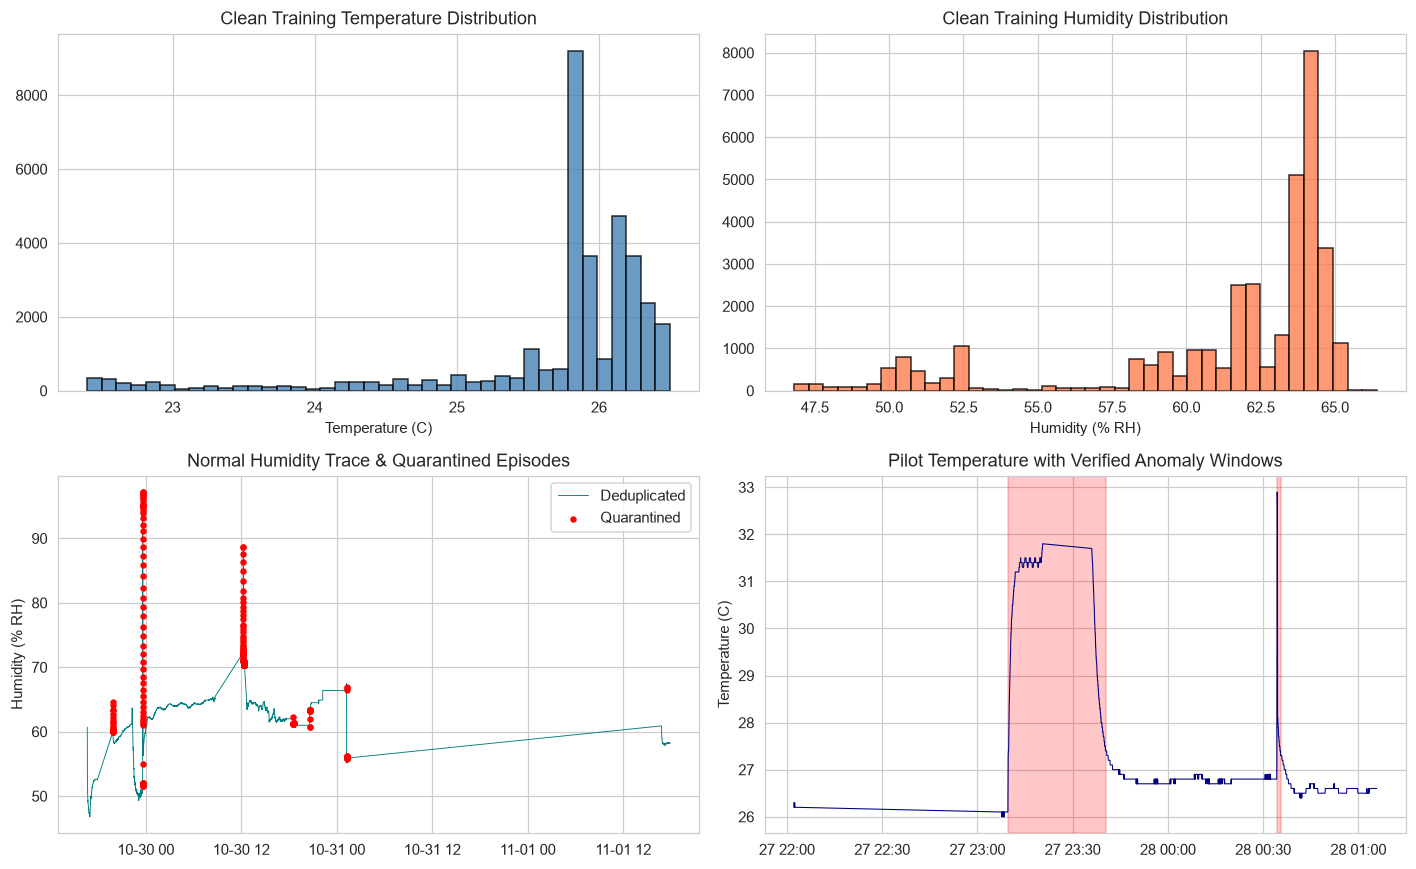

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

axes[0, 0].hist(clean_normal['temperature'], bins=40, color='steelblue', edgecolor='black', alpha=0.8)
axes[0, 0].set_title('Clean Training Temperature Distribution')
axes[0, 0].set_xlabel('Temperature (C)')

axes[0, 1].hist(clean_normal['humidity'], bins=40, color='coral', edgecolor='black', alpha=0.8)
axes[0, 1].set_title('Clean Training Humidity Distribution')
axes[0, 1].set_xlabel('Humidity (% RH)')

axes[1, 0].plot(dedup['timestamp'], dedup['humidity'], color='teal', linewidth=0.6, label='Deduplicated')
if len(quarantined):
    axes[1, 0].scatter(quarantined['timestamp'], quarantined['humidity'], color='red', s=10, zorder=5, label='Quarantined')
axes[1, 0].set_title('Normal Humidity Trace & Quarantined Episodes')
axes[1, 0].set_ylabel('Humidity (% RH)')
axes[1, 0].legend()

axes[1, 1].plot(pilot['timestamp'], pilot['temperature'], color='navy', linewidth=0.7, label='Pilot T')
for _, r in pilot_ann.iterrows():
    axes[1, 1].axvspan(pd.to_datetime(r['start_time']), pd.to_datetime(r['end_time']), color='red', alpha=0.22)
axes[1, 1].set_title('Pilot Temperature with Verified Anomaly Windows')
axes[1, 1].set_ylabel('Temperature (C)')

plt.tight_layout()
plt.show()